#### Graph Convolutional Networks (GCNs):
- Dataset Cora representing scientific publications across 7 classes.
- Model, a 2-layer GCN using PyTorch Geometric (GCNConv)
- Final embeddings visualized in 2D using PCA.

In [ ]:
!pip install torch torch_geometric > /dev/null

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Math, Latex

import networkx as nx

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.datasets import Planetoid
from torch_geometric.transforms import NormalizeFeatures
from torch_geometric.utils import to_networkx
from torch_geometric.nn import GCNConv

%matplotlib inline

#### Dataset Cora

Processing...
Done!
/usr/local/lib/python3.13/dist-packages/torch_geometric/data/summary.py:34: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/ReduceOps.cpp:1913.)
  std=data.std().item(),


Dataset Summary: Planetoid (#graphs=1):
+------------+----------+----------+
|            |   #nodes |   #edges |
|------------+----------+----------|
| mean       |     2708 |    10556 |
| std        |      nan |      nan |
| min        |     2708 |    10556 |
| quantile25 |     2708 |    10556 |
| median     |     2708 |    10556 |
| quantile75 |     2708 |    10556 |
| max        |     2708 |    10556 |
+------------+----------+----------+
threshold 0.011821204285186553


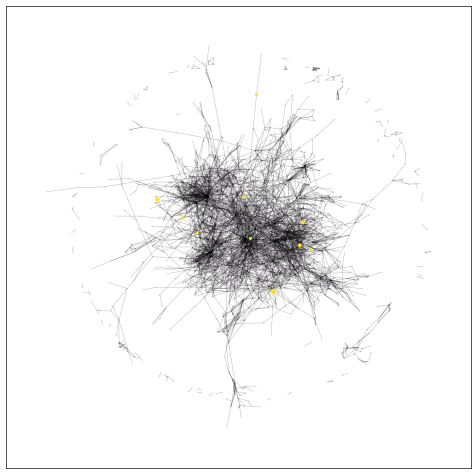

In [ ]:
''' Dataset Cora '''
dataset = Planetoid(root='Planetoid', name='Cora',transform=NormalizeFeatures())

print(f'Dataset Summary: {dataset.get_summary()}')
data = dataset[0]  # Get the first graph object.

''' Visualize the nodes with the highest degree of centrality '''
G = to_networkx(data, to_undirected=True)
pos = nx.spring_layout(G, seed=42)
degree_centrality = nx.degree_centrality(G)
degree_centrality_array = np.array(list(degree_centrality.values()))
node_size = list(map(lambda x: x*500, degree_centrality.values()))
threshold = sorted(degree_centrality_array, reverse=True)[10]
sorted_degree_centrality = dict(sorted(degree_centrality.items(), key=lambda x: x[1], reverse=True))
centrality_bin = np.where(degree_centrality_array > threshold, 1, 0.1)

plt.figure(figsize=(10, 10), dpi=60)

nodes_ = nx.draw_networkx_nodes(
    G, pos,
    node_size=node_size, node_color=centrality_bin, #cmap=plt.cm.Reds,
    nodelist = list(sorted_degree_centrality.keys()),
    alpha = centrality_bin, label=True)

edges_ = nx.draw_networkx_edges(G, pos, alpha=0.3, width=0.5)
print('threshold', threshold)
plt.show()

#### Graph Embedding with Cora Dataset

In [ ]:
''' Two layer GCN model '''
class GCN(torch.nn.Module):
    def __init__(self, hidden_channels):
        super(GCN, self).__init__()
        self.conv1 = GCNConv(dataset.num_node_features, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, dataset.num_classes)
        self.dropout = nn.Dropout(p=0.5)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, training=self.training)
        x = self.conv2(x, edge_index)
        return x


'''Train the model on the training nodes '''
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = GCN(hidden_channels=16).to(device)
data = dataset[0].to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)

model.train()
for epoch in range(1000):
    optimizer.zero_grad()
    out = model(data)
    loss = F.cross_entropy(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()

model.eval()
with torch.no_grad():
    embedding_pyg = model(data).cpu().numpy()
print('Final embeddings shape', embedding_pyg.shape)
print('Final embeddings using GCN in PyG', embedding_pyg)

Final embeddings shape (2708, 7)
Final embeddings using GCN in PyG [[-1.2522315  -0.72821325 -0.6572226  ...  0.03640723 -2.321089
  -0.8688662 ]
 [ 0.12906563 -1.95121    -1.2576125  ...  5.0091395  -1.5987804
  -1.3226142 ]
 [ 0.04181659 -1.467865   -1.31439    ...  3.9608188  -2.0260506
  -1.6124674 ]
 ...
 [ 1.526702    1.7746761  -3.2290995  ... -2.7513542   0.87077034
   0.29741952]
 [-0.78369    -0.5327917  -0.39551795 ...  0.75774026 -2.289789
  -1.7768581 ]
 [-0.78366584 -0.301282   -0.25709844 ...  0.42488992 -1.8842576
  -1.6957414 ]]


#### Embedding visualization

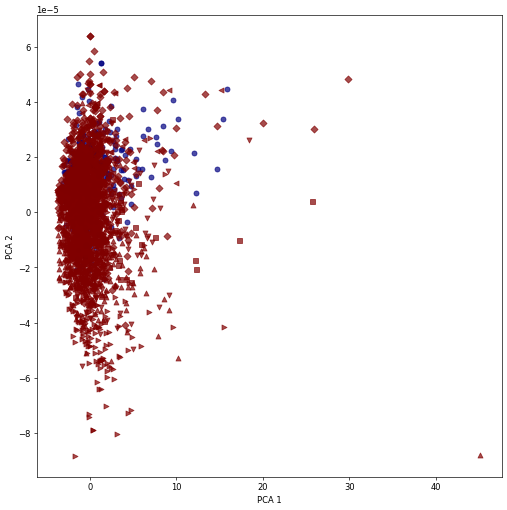

In [ ]:
pipeline = Pipeline([('scaler', StandardScaler()), ('pca', PCA(n_components=2))])
embedding_sklearn = pipeline.fit_transform(embedding_pyg)

# class labels for each node
labels = data.y.cpu().numpy()

plt.figure(figsize=(10, 10), dpi=60)
markers = ['o', 's', '^', 'D', 'v', '>', '<', 'p', '*', 'H']

for idx, subject in enumerate(np.unique(labels)):
    indices = np.where(labels == subject)
    plt.scatter(embedding_sklearn[indices, 0],
                embedding_sklearn[indices, 1],
                color=plt.cm.jet(idx / len(indices)),
                marker=markers[idx], alpha=0.7
    )

plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.show()